**Part 1**: Read external data source

In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as plt
import sys
from pathlib import Path


Data Source: 

In [2]:
raw = pd.read_csv("../data/raw/world_dev_indicators_data.csv")
print(raw.head())
raw.dtypes


  Country Name Country Code  \
0  Afghanistan          AFG   
1  Afghanistan          AFG   
2  Afghanistan          AFG   
3  Afghanistan          AFG   
4  Afghanistan          AFG   

                                         Series Name        Series Code  \
0                              GDP growth (annual %)  NY.GDP.MKTP.KD.ZG   
1              Inflation, consumer prices (annual %)     FP.CPI.TOTL.ZG   
2  Unemployment, total (% of total labor force) (...  SL.UEM.TOTL.NE.ZS   
3       Domestic credit to private sector (% of GDP)  FS.AST.PRVT.GD.ZS   
4                                   Trade (% of GDP)     NE.TRD.GNFS.ZS   

       2020 [YR2020]      2021 [YR2021]      2022 [YR2022]      2023 [YR2023]  \
0  -2.35110067203466  -20.7388393676343  -6.24017199240269   2.26694373649188   
1   5.60188791482224   5.13320340824962   13.7121023720064  -4.64470870797774   
2              11.71              5.679                 ..                 ..   
3   3.09659808966059                 .

Country Name     str
Country Code     str
Series Name      str
Series Code      str
2020 [YR2020]    str
2021 [YR2021]    str
2022 [YR2022]    str
2023 [YR2023]    str
2024 [YR2024]    str
2025 [YR2025]    str
dtype: object

In [6]:
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

from src.functions import clean_data, reshape_data, summary_by_country
df_clean = clean_data(raw)
df_reshape = reshape_data(df_clean)
df_summary = summary_by_country(df_reshape)



**Part 3**: Exploratory Analysis

Question 1: Which Country has the highest mean inflation?

In [10]:
print(f"The country with highest inflation is {df_summary["inflation_mean"].idxmax()} with an average inflation from 2020-2025 of {df_summary["inflation_mean"].max()}")

The country with highest inflation is Zimbabwe with an average inflation from 2020-2025 of 253.48


Question 2: Which country saw the highest GDP growth, and in what year?

In [34]:
print(f"The country with highest GDP growth was {df_reshape.loc[df_reshape["gdp_growth"].idxmax()]['country']} with a max growth of {round(df_reshape.loc[df_reshape["gdp_growth"].idxmax()]['gdp_growth'],2)} in {df_reshape.loc[df_reshape["gdp_growth"].idxmax()]['year']}")

The country with highest GDP growth was Macao SAR, China with a max growth of 75.31 in 2023


**Part 4**: Visualization

Plot One:

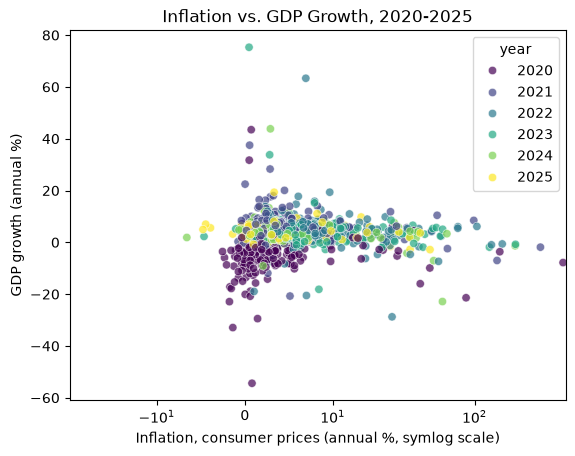

In [47]:
relation_plot_data = df_reshape.dropna(subset = ["inflation","gdp_growth"])
plot = sns.scatterplot(
    data=relation_plot_data, x="inflation",y="gdp_growth",
    hue = "year", palette="viridis", alpha=0.7
)
plot.set_xscale("symlog", linthresh=15)
plot.set(
    title="Inflation vs. GDP Growth, 2020-2025",
    xlabel="Inflation, consumer prices (annual %, symlog scale)",
    ylabel="GDP growth (annual %)",
)
plot.figure.savefig(
    "../figures/"
    "Inflation_GDP_Growth.png",
    dpi=300,
    bbox_inches="tight"
    
    )

When comparing inflation and GDP growth, there does not seem to be a relationship between the two. One interesting factor is that we can visually see the COVID-19 pandemic. The cluster of purple dots represent the year 2020, nearly every country was facing stagnant growth as well as low inflation due to the lack of spending. 

Plot 2:

In [50]:
df_reshape.head()

,country,country_code,year,inflation,private_credit,trade,gdp_growth,unemployment
0,Afghanistan,AFG,2020,5.601888,3.096598,46.709895,-2.351101,11.710
1,Afghanistan,AFG,2021,5.133203,NaN,51.411716,-20.738839,5.679
2,Afghanistan,AFG,2022,13.712102,NaN,72.885470,-6.240172,NaN
3,Afghanistan,AFG,2023,-4.644709,NaN,66.999578,2.266944,NaN
4,Afghanistan,AFG,2024,-6.601186,NaN,83.763025,1.873193,NaN


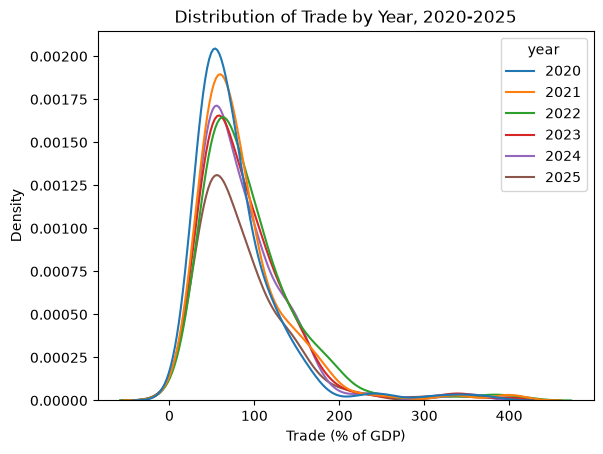

In [62]:
trade_data = df_reshape.dropna(subset=["trade"]).assign(year=lambda d: d["year"].astype(str))
trade_density = sns.kdeplot(
    data=trade_data, x="trade", hue ="year"
)
trade_density.set(
    title="Distribution of Trade by Year, 2020-2025",
    xlabel="Trade (% of GDP)",
    ylabel="Density",
)
trade_density.figure.savefig(
    "../figures/"
    "Dist_of_trade.png",
    dpi=300,
    bbox_inches="tight"
)


This is another fascinating visual of the way that the COVID pandemic affected the global economy. The light blue line, being 2020, has the tightest density around 80% of GDP, and as time goes forward the density flattens by 2025 (the brown line). This shows the way that trade shrank during COVID, and as the pandemic lessened and global trade recovered it expanded. 

Plot 3: Inflation and Trade

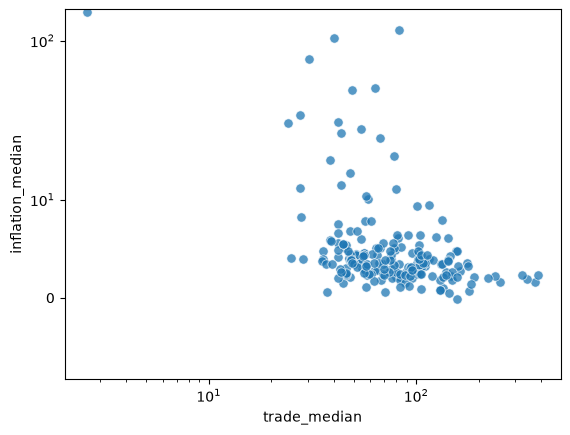

In [70]:
inflation_trade_data = df_summary.dropna(subset=["trade_median","inflation_median"])
scatter=sns.scatterplot(
    data = inflation_trade_data,
    x="trade_median",
    y="inflation_median",
    alpha = 0.75,
    s=45
)
scatter.set_xscale("log")
scatter.set_yscale("symlog",linthresh=15)
